In [0]:

from pyspark.sql import functions as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = spark.table(
    "workspace.default.freddie_model_split"
)

train = df.filter(F.col("split") == "train")

# Confirm training data
display(
    train.groupBy("event_type")
    .agg(
        F.count("*").alias("n_loans"),
        F.round(F.avg("time_months"), 1)
            .alias("avg_followup")
    )
    .orderBy("event_type")
)

print("Training loans:", train.count())


event_type,n_loans,avg_followup
0,7580,105.9
1,2048,37.2
2,25289,39.1
3,58,8.6


Training loans: 34975


In [0]:

# Aggregate monthly outcomes using PySpark
monthly_counts = (
    train.groupBy("time_months", "event_type")
    .count()
    .collect()
)

counts = {
    (int(r["time_months"]), int(r["event_type"])):
        int(r["count"])
    for r in monthly_counts
}

n_total = train.count()
max_month = max(t for t, e in counts)

# Initialize survival and cumulative incidence
n_risk = n_total
s_all = 1.0
s_km = 1.0
cif_dpd = 0.0

results = []

for month in range(1, max_month + 1):

    c = counts.get((month, 0), 0)
    d1 = counts.get((month, 1), 0)
    d2 = counts.get((month, 2), 0)
    d3 = counts.get((month, 3), 0)

    if n_risk <= 0:
        break

    total_events = d1 + d2 + d3

    assert total_events + c <= n_risk

    # Aalen-Johansen: cumulative incidence of 90+ DPD
    cif_dpd += s_all * d1 / n_risk

    # Overall event-free survival
    s_all *= (1 - total_events / n_risk)

    # KM: treat competing events as censored
    s_km *= (1 - d1 / n_risk)

    results.append((
        month, n_risk, d1, d2, d3, c,
        cif_dpd, 1 - s_km
    ))

    # Remove all exits, including censoring,
    # from the next month's risk set
    n_risk -= total_events + c

assert n_risk == 0

curve = spark.createDataFrame(
    results,
    schema="""
        month INT,
        n_at_risk INT,
        dpd_events INT,
        payoff_events INT,
        other_events INT,
        censored INT,
        aj_cif DOUBLE,
        km_risk DOUBLE
    """
)

display(curve.orderBy("month"))


month,n_at_risk,dpd_events,payoff_events,other_events,censored,aj_cif,km_risk
1,34975,0,62,0,0,0.0,0.0
2,34913,0,81,0,0,0.0,0.0
3,34832,15,96,1,0,4.2887776983559683E-4,4.306384933394636E-4
4,34720,13,116,5,0,8.005718370264474E-4,8.049012151016832E-4
5,34586,20,201,10,0,0.0013724088634739099,0.0013827044295727786
6,34355,14,236,9,0,0.0017726947819871335,0.0017896507878317758
7,34096,20,189,7,0,0.0023445318084345957,0.002375180086994333
8,33880,14,191,4,0,0.0027448177269478193,0.002787421748115415
9,33671,18,189,7,0,0.0032594710507505356,0.0033205162926354115
10,33457,13,205,6,0,0.0036311651179413863,0.0037077845261349607


In [0]:

risk_summary = (
    curve
    .filter(F.col("month").isin(12, 24, 36))
    .select(
        "month",
        "n_at_risk",
        F.round(
            100 * F.col("aj_cif"), 2
        ).alias("aj_risk_pct"),
        F.round(
            100 * F.col("km_risk"), 2
        ).alias("km_risk_pct"),
        F.round(
            100 * (
                F.col("km_risk") - F.col("aj_cif")
            ), 2
        ).alias("difference_pp")
    )
    .orderBy("month")
)

display(risk_summary)


month,n_at_risk,aj_risk_pct,km_risk_pct,difference_pp
12,33025,0.42,0.43,0.01
24,29999,0.84,0.89,0.05
36,22605,3.32,4.22,0.9


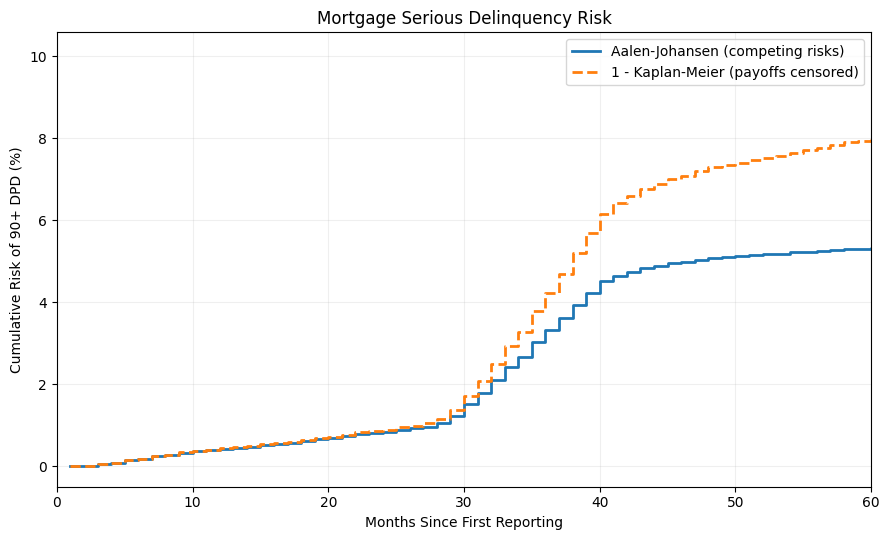

In [0]:

plot_df = curve.orderBy("month").toPandas()

plt.figure(figsize=(9, 5.5))

plt.step(
    plot_df["month"],
    100 * plot_df["aj_cif"],
    where="post",
    linewidth=2,
    label="Aalen-Johansen (competing risks)"
)

plt.step(
    plot_df["month"],
    100 * plot_df["km_risk"],
    where="post",
    linewidth=2,
    linestyle="--",
    label="1 - Kaplan-Meier (payoffs censored)"
)

plt.xlabel("Months Since First Reporting")
plt.ylabel("Cumulative Risk of 90+ DPD (%)")
plt.title("Mortgage Serious Delinquency Risk")
plt.xlim(0, 60)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [0]:

# Basic mathematical checks
qc = curve.agg(
    F.min("aj_cif").alias("min_cif"),
    F.max("aj_cif").alias("max_cif"),
    F.max(
        F.col("aj_cif") - F.col("km_risk")
    ).alias("max_aj_minus_km"),
    F.min("n_at_risk").alias("min_risk_set")
)

display(qc)


min_cif,max_cif,max_aj_minus_km,min_risk_set
0.0,0.059102712591847975,0.0,9


In [0]:

# Examine the sharp increase around months 30-40
display(
    curve.filter(
        F.col("month").between(28, 42)
    )
    .select(
        "month",
        "n_at_risk",
        "dpd_events",
        "payoff_events",
        "other_events",
        "censored",
        "aj_cif",
        "km_risk"
    )
    .orderBy("month")
)


month,n_at_risk,dpd_events,payoff_events,other_events,censored,aj_cif,km_risk
28,28374,28,461,0,0,0.010436025732666191,0.011378844033114288
29,27885,62,519,0,0,0.012208720514653326,0.013576961718965053
30,27304,101,577,0,0,0.015096497498213013,0.017225831000622804
31,26626,98,613,0,0,0.01789849892780558,0.02084304231895595
32,25915,108,682,0,0,0.02098641887062188,0.02492365013024489
33,25125,114,673,1,0,0.024245889921372415,0.02934787715054943
34,24337,87,739,0,0,0.026733380986418878,0.032817768044575035
35,23511,125,781,0,0,0.03030736240171552,0.03795994740718944
36,22605,100,760,1,0,0.03316654753395283,0.042215820234408286
37,21744,108,789,0,0,0.03625446747676913,0.04697302642529699


In [0]:



train = spark.table(
    "workspace.default.freddie_model_split"
).filter(F.col("split") == "train")

fico_data = (
    train
    .filter(F.col("fico").isNotNull())
    .withColumn(
        "fico_group",
        F.when(F.col("fico") < 700, "<700")
         .when(F.col("fico") < 760, "700-759")
         .otherwise(">=760")
    )
)

display(
    fico_data.groupBy("fico_group")
    .agg(
        F.count("*").alias("n_loans"),
        F.sum("event").alias("n_events")
    )
    .orderBy("fico_group")
)


fico_group,n_loans,n_events
700-759,12856,850
<700,6493,777
>=760,15619,421


In [0]:

import pandas as pd
import matplotlib.pyplot as plt

# Aggregated counts by FICO group, month, and event type
records = (
    fico_data
    .groupBy("fico_group", "time_months", "event_type")
    .count()
    .collect()
)

counts = {
    (r["fico_group"], int(r["time_months"]),
     int(r["event_type"])): int(r["count"])
    for r in records
}

group_sizes = {
    r["fico_group"]: int(r["count"])
    for r in fico_data.groupBy("fico_group").count().collect()
}

results = []

for group in ["<700", "700-759", ">=760"]:
    n_risk = group_sizes[group]
    s_all = 1.0
    cif = 0.0

    for month in range(1, 37):
        if n_risk <= 0:
            break

        d1 = counts.get((group, month, 1), 0)
        d2 = counts.get((group, month, 2), 0)
        d3 = counts.get((group, month, 3), 0)
        censored = counts.get((group, month, 0), 0)

        total_events = d1 + d2 + d3

        cif += s_all * d1 / n_risk
        s_all *= (1 - total_events / n_risk)

        results.append({
            "fico_group": group,
            "month": month,
            "n_at_risk": n_risk,
            "cif": cif
        })

        n_risk -= total_events + censored

fico_cif = pd.DataFrame(results)

# Risk at selected horizons
display(
    fico_cif[
        fico_cif["month"].isin([12, 24, 36])
    ].copy()
)


fico_group,month,n_at_risk,cif
<700,12,6054,0.011550900970275679
<700,24,5377,0.023101801940551368
<700,36,4024,0.07007546588633913
700-759,12,12204,0.0034225264467952704
700-759,24,11053,0.007700684505289359
700-759,36,8216,0.03671437461107654
>=760,12,14760,0.0017926883923426592
>=760,24,13564,0.002817081759395608
>=760,36,10362,0.014917728407708556


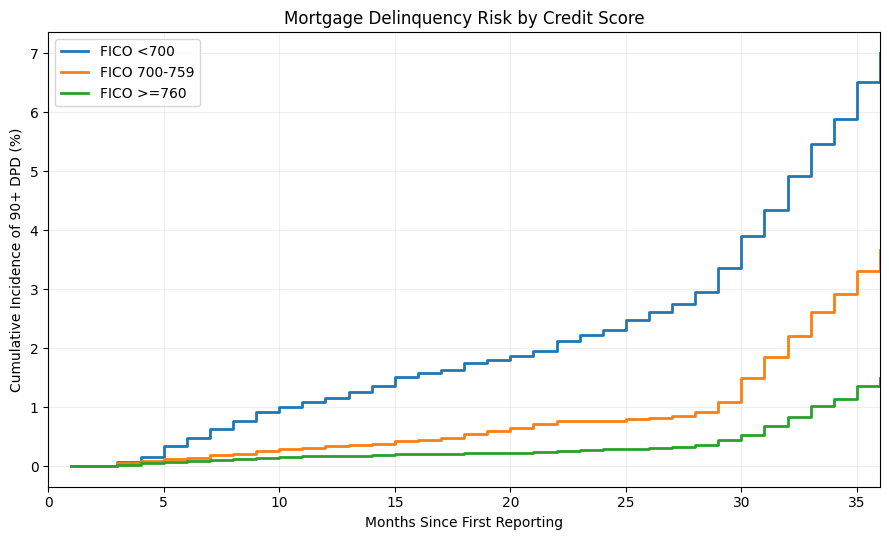

In [0]:

plt.figure(figsize=(9, 5.5))

for group in ["<700", "700-759", ">=760"]:
    d = fico_cif[fico_cif["fico_group"] == group]

    plt.step(
        d["month"],
        100 * d["cif"],
        where="post",
        linewidth=2,
        label=f"FICO {group}"
    )

plt.xlabel("Months Since First Reporting")
plt.ylabel("Cumulative Incidence of 90+ DPD (%)")
plt.title("Mortgage Delinquency Risk by Credit Score")
plt.xlim(0, 36)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
